# Reproducing the experiments

This notebook re-runs **every experiment** reported in the README, step by step, and compares the numbers
with the submitted ones.

| step | what it reproduces | time |
|---|---|---|
| 1 | dataset statistics and the leakage check | seconds |
| 2 | *(only with the raw file)* data preparation and the label-audit counts | seconds |
| 3 | the TF-IDF + logistic-regression baseline | ~10 s |
| 4 | **exact check:** the published model on the test set must give F1 = 0.931 | ~1 min |
| 5 | fine-tuning XLM-R from scratch with `config.json` | ~7 min on Apple M5, a few min on a Colab T4 |
| 6 | *(optional)* the learning-rate sweep | 3 × step 5 |
| 7 | threshold selection on validation | ~30 s |
| 8 | one evaluation on the test set, confusion matrices, bootstrap CI | ~30 s |
| 9 | error analysis and a summary table | seconds |

Everything this notebook writes goes to `repro/` (git-ignored), so the committed `results/` stay untouched.

**Colab:** *Runtime → Change runtime type → T4 GPU*, then *Run all*.
**Locally:** open this notebook from the repository (`notebooks/`) after `pip install -r requirements.txt`.

## 0. Setup

In [1]:
import os, sys, json, time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/zhanel00/kazakh-profanity-detection.git"
HF_MODEL_ID = "Zhanel00/kazakh-profanity-xlmr"

if IN_COLAB:
    if not Path("kazakh-profanity-detection").exists():
        !git clone -q $REPO_URL kazakh-profanity-detection
    %cd kazakh-profanity-detection
    # Colab already ships torch; install the remaining pinned packages
    !pip -q install transformers==5.6.2 tokenizers==0.22.2 sentencepiece==0.2.1 huggingface_hub==1.12.0 accelerate==1.13.0 scikit-learn==1.6.1
elif Path.cwd().name == "notebooks":
    os.chdir("..")                      # run everything from the repository root
print("repository root:", Path.cwd().name)

repository root: kazakh-profanity-detection


In [2]:
# ---- what to run --------------------------------------------------------------------
RUN_TRAIN = not Path("repro/model/model.safetensors").exists()   # step 5: fine-tune XLM-R (skipped if repro/ already
                                                                 # has a model - delete repro/ to train again)
RUN_LR_SWEEP = False    # step 6: three more training runs (lr 2e-5, 3e-5, 5e-5)
RAW_CSV = Path("data/raw/kazakh_profanity_share.csv")
RUN_PREPARE = RAW_CSV.exists()          # step 2 needs the raw file, which is not public

In [3]:
import numpy as np, pandas as pd, torch, transformers, sklearn
import matplotlib.pyplot as plt
from src.model_utils import get_device

print(f"python {sys.version.split()[0]} | torch {torch.__version__} | transformers {transformers.__version__} "
      f"| scikit-learn {sklearn.__version__}")
print("device:", get_device())
pd.set_option("display.max_colwidth", 120)

# every run gets its own config file that points its outputs into repro/
BASE = json.loads(Path("config.json").read_text())
REPRO = Path("repro"); REPRO.mkdir(exist_ok=True)

def make_config(name, **override):
    path = REPRO / f"config_{name}.json"
    path.write_text(json.dumps({**BASE, **override}, indent=2))
    return str(path)

CFG = make_config("main", output_dir="repro/model", results_dir="repro/results")
CFG_SUBMITTED = make_config("submitted", results_dir="repro/submitted_model_results")
CFG_PREPARE = make_config("prepare", processed_dir="repro/processed")
print(json.dumps({k: BASE[k] for k in ("seed", "model_name", "learning_rate", "batch_size",
                                       "num_epochs", "max_length", "window_stride",
                                       "freeze_word_embeddings")}, indent=1))

python 3.13.9 | torch 2.14.1 | transformers 5.6.2 | scikit-learn 1.6.1
device: mps
{
 "seed": 42,
 "model_name": "FacebookAI/xlm-roberta-base",
 "learning_rate": 3e-05,
 "batch_size": 16,
 "num_epochs": 6,
 "max_length": 128,
 "window_stride": 64,
 "freeze_word_embeddings": true
}


## 1. Data and the leakage check
The anonymised, de-duplicated splits are committed in `data/processed/`. Each row carries the id of its
near-duplicate group (character 3–5-gram TF-IDF, cosine ≥ 0.9), so we can check that no group, and no
identical text, appears in two splits.

In [4]:
D = Path(BASE["processed_dir"])
splits = {s: pd.read_csv(D / f"{s}.csv") for s in ("train", "val", "test")}

stats = pd.DataFrame({s: {"texts": len(d), "clean (0)": int((d.label == 0).sum()),
                          "profane (1)": int((d.label == 1).sum()),
                          "profane share": f"{d.label.mean():.1%}"} for s, d in splits.items()}).T
stats.loc["total"] = [sum(len(d) for d in splits.values()),
                      sum(int((d.label == 0).sum()) for d in splits.values()),
                      sum(int((d.label == 1).sum()) for d in splits.values()), ""]
display(stats)

groups = {s: set(d.group) for s, d in splits.items()}
texts = {s: set(d.text.str.lower().str.strip()) for s, d in splits.items()}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a:5s} ∩ {b:4s}: shared near-duplicate groups = {len(groups[a] & groups[b])}, "
          f"identical texts = {len(texts[a] & texts[b])}")

,texts,clean (0),profane (1),profane share
train,2520,1299,1221,48.5%
val,265,109,156,58.9%
test,265,109,156,58.9%
total,3050,1517,1533,


train ∩ val : shared near-duplicate groups = 0, identical texts = 0
train ∩ test: shared near-duplicate groups = 0, identical texts = 0
val   ∩ test: shared near-duplicate groups = 0, identical texts = 0


In [5]:
tr = splits["train"]
n_chars = tr.text.str.len()
print("median length:", int(n_chars.median()), "characters")
print(f"profane share in train: texts < 30 chars = {tr.label[n_chars < 30].mean():.0%}, "
      f"longer texts = {tr.label[n_chars >= 30].mean():.0%}   <- the 'short = profane' bias (error analysis)")
tr.sample(6, random_state=0)[["text", "label"]]

median length: 38 characters
profane share in train: texts < 30 chars = 58%, longer texts = 42%   <- the 'short = profane' bias (error analysis)


,text,label
841,Қотағымды жеп қалған прложене екен бар ғой е автобусға төйли алмайсың загрузка болып тұра береді қотағымды жеп қалға...,1
1988,Зайбал адам уксап шгарса боадыго биррет истесе бир жагы куып калад адам уқсап істендерш еш,1
1412,Керемет қолданыңдар,0
2428,Сондай жаман том мыйын ашытып шығарады! Жаман 2 жұлдыз қойдым достар мен оны 2020 жылы ойнадым ##### бұл ойын жаманғ...,0
2179,"Маскарасындаргой,акцияларын ужасный далбаса",0
924,Ебат фф чит скачат етім күшті екек топ,1


## 2. Data preparation and label audit *(only with the raw file)*
`src.prepare_data` anonymises, applies the 19 documented label revisions, removes exact duplicates, groups
near-duplicates and repairs leakage between the provided splits. Here it writes to `repro/processed/` and
we check that it produces exactly the committed splits. `src.audit_labels` reproduces the counts of rows
that were read by hand during the label audit (157 + 246).

In [6]:
if RUN_PREPARE:
    !python -m src.prepare_data --config $CFG_PREPARE
    for s, committed in splits.items():
        rebuilt = pd.read_csv(f"repro/processed/{s}.csv")
        same = (rebuilt[["id", "text", "label"]].reset_index(drop=True)
                .equals(committed[["id", "text", "label"]].reset_index(drop=True)))
        print(f"{s:5s}: {len(rebuilt)} rows, identical to data/processed/{s}.csv -> {same}")
    print()
    !python -m src.audit_labels
else:
    print("Raw file not found (it is not public, see data/raw/README.md) - "
          "using the committed splits in data/processed/.")

{
  "raw_rows": 3061,
  "raw_label_counts": {
    "0": 1522,
    "1": 1539
  },
  "rows_anonymised": 24,
  "labels_revised": {
    "0->1": 11,
    "1->0": 8
  },
  "exact_duplicates_removed": 11,
  "near_duplicate_groups(size>1)": 14,
  "rows_in_near_duplicate_groups": 31,
  "split_strategy": "provided split column, near-duplicate groups moved to their majority split",
  "rows_moved_to_fix_leakage": 6,
  "final_rows": 3050,
  "splits": {
    "train": {
      "n": 2520,
      "label_0": 1299,
      "label_1": 1221,
      "profane_share": 0.485
    },
    "val": {
      "n": 265,
      "label_0": 109,
      "label_1": 156,
      "profane_share": 0.589
    },
    "test": {
      "n": 265,
      "label_0": 109,
      "label_1": 156,
      "profane_share": 0.589
    }
  },
  "seed": 42
}


train: 2520 rows, identical to data/processed/train.csv -> True
val  : 265 rows, identical to data/processed/val.csv -> True
test : 265 rows, identical to data/processed/test.csv -> True



85 stems | rows=3061
label 0 with a stem   (0hit):  157
label 1 without stem (1miss): 246


## 3. Baseline: character n-gram TF-IDF + logistic regression
A purely lexical reference model. The TF-IDF vocabulary and the classifier are fitted on train only;
the threshold is chosen on validation.

In [7]:
!PYTHONWARNINGS=ignore python -m src.baseline --config $CFG > /dev/null
baseline = json.loads(Path("repro/results/baseline_metrics.json").read_text())

def row(rep):
    return {"threshold": rep["threshold"], "precision": rep["precision_profane"],
            "recall": rep["recall_profane"], "F1": rep["f1_profane"], "accuracy": rep["accuracy"]}

pd.DataFrame({"baseline val": row(baseline["val"]), "baseline test": row(baseline["test"])}).T.round(3)

,threshold,precision,recall,F1,accuracy
baseline val,0.41,0.973,0.923,0.947,0.940
baseline test,0.41,0.905,0.917,0.911,0.894


## 4. Exact check: the submitted model
Inference is deterministic, so running the **published weights** on the committed test split must give
exactly the submitted numbers (F1 0.931, TN 94 / FP 15 / FN 7 / TP 149). The local copy in
`artifacts/model` is used if it exists, otherwise the model is downloaded from the Hugging Face Hub (1.1 GB).

In [8]:
SUBMITTED_MODEL = "artifacts/model" if Path("artifacts/model/model.safetensors").exists() else HF_MODEL_ID
print("model:", SUBMITTED_MODEL)
!python -m src.evaluate --config $CFG_SUBMITTED --model $SUBMITTED_MODEL > /dev/null

submitted = json.loads(Path("results/test_metrics.json").read_text())          # committed results
rerun = json.loads(Path("repro/submitted_model_results/test_metrics.json").read_text())
for k in ("precision_profane", "recall_profane", "f1_profane", "accuracy"):
    print(f"{k:18s} committed {submitted[k]:.4f} | re-run {rerun[k]:.4f}")
print("confusion matrix  committed", submitted["confusion_matrix"], "| re-run", rerun["confusion_matrix"])
print("EXACT MATCH" if rerun["confusion_matrix"] == submitted["confusion_matrix"] else "MISMATCH")

model: artifacts/model


Loading weights: 100%|██████████████████████| 201/201 [00:00<00:00, 7499.16it/s]


precision_profane  committed 0.9085 | re-run 0.9085
recall_profane     committed 0.9551 | re-run 0.9551
f1_profane         committed 0.9313 | re-run 0.9313
accuracy           committed 0.9170 | re-run 0.9170
confusion matrix  committed {'tn': 94, 'fp': 15, 'fn': 7, 'tp': 149} | re-run {'tn': 94, 'fp': 15, 'fn': 7, 'tp': 149}
EXACT MATCH


## 5. Fine-tuning XLM-RoBERTa-base from scratch
`src.train` with the settings in `config.json`:

* cross-entropy over 2 classes; AdamW with lr 3e-5 and weight decay 0.01;
* 10% linear warm-up, then linear decay; gradient clipping at 1.0; batch 16; inputs truncated to 128 tokens;
* the 250k × 768 word-embedding matrix is frozen, so 86M of the 278M parameters are trained;
* up to 6 epochs: the epoch with the best validation F1 is kept, with early stopping (patience 2);
* the decision threshold is then tuned on validation (grid 0.20–0.80).

GPU / MPS training is **not deterministic** even with a fixed seed, so a new run gives a different model.
In the committed run below (Apple M5, MPS) it reached test F1 0.912 instead of 0.931 (see step 9 and the README).

In [9]:
if RUN_TRAIN:
    t0 = time.time()
    !python -m src.train --config $CFG
    print(f"\ntraining + threshold tuning took {(time.time() - t0) / 60:.1f} min")
else:
    print("Skipped: repro/model already exists (delete repro/ to train again)." if Path("repro/model").exists()
          else "RUN_TRAIN = False - the plots below use the committed training log.")

Skipped: repro/model already exists (delete repro/ to train again).


,epoch,train_loss,val_loss,val_f1@0.5,val_precision@0.5,val_recall@0.5,seconds
0,1,0.591,0.498,0.825,0.958,0.724,81.7
1,2,0.320,0.303,0.934,0.919,0.949,81.9
2,3,0.226,0.261,0.940,0.920,0.962,81.1
3,4,0.154,0.398,0.922,0.940,0.904,82.3
4,5,0.093,0.379,0.954,0.922,0.987,84.8
5,6,0.076,0.375,0.939,0.936,0.942,81.7


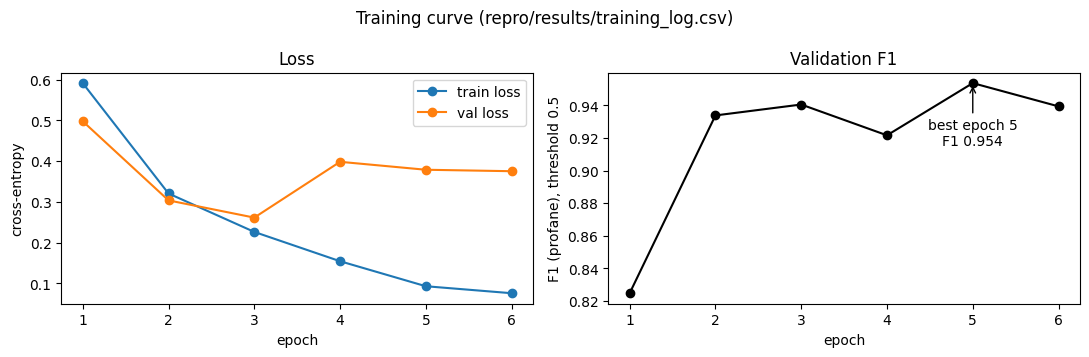

The checkpoint is chosen by validation F1, not by validation loss or the last epoch: the loss starts rising once the model becomes over-confident on its few mistakes, while F1 can still improve.


In [10]:
TRAINED = Path("repro/model/model.safetensors").exists()
log_path = Path("repro/results/training_log.csv") if TRAINED else Path("results/training_log.csv")
log = pd.read_csv(log_path)
display(log.round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot(log.epoch, log.train_loss, "o-", label="train loss")
a1.plot(log.epoch, log.val_loss, "o-", label="val loss")
a1.set_xlabel("epoch"); a1.set_ylabel("cross-entropy"); a1.legend(); a1.set_title("Loss")
a2.plot(log.epoch, log["val_f1@0.5"], "o-", color="black")
best = log.loc[log["val_f1@0.5"].idxmax()]
a2.annotate(f"best epoch {int(best.epoch)}\nF1 {best['val_f1@0.5']:.3f}", (best.epoch, best["val_f1@0.5"]),
            xytext=(0, -45), textcoords="offset points", ha="center", arrowprops=dict(arrowstyle="->"))
a2.set_xlabel("epoch"); a2.set_ylabel("F1 (profane), threshold 0.5"); a2.set_title("Validation F1")
fig.suptitle(f"Training curve ({log_path})"); fig.tight_layout(); plt.show()
print("The checkpoint is chosen by validation F1, not by validation loss or the last epoch: the loss starts rising "
      "once the model becomes over-confident on its few mistakes, while F1 can still improve.")

## 6. Learning-rate sweep *(optional)*
The submitted model uses lr 3e-5, chosen on validation from {2e-5, 3e-5, 5e-5}. With `RUN_LR_SWEEP = False`
the table shows the committed sweep logs in `results/lr_sweep/`.

In [11]:
LRS = ["2e-5", "3e-5", "5e-5"]
if RUN_LR_SWEEP:
    for lr in LRS:
        print(f"===== lr {lr}")
        !python -m src.train --config $CFG --lr $lr --output_dir repro/lr_sweep/lr$lr/model --results_dir repro/lr_sweep/lr$lr > repro/lr_sweep_$lr.log 2>&1
sweep_root = Path("repro/lr_sweep") if RUN_LR_SWEEP else Path("results/lr_sweep")
rows = {}
for lr in LRS:
    vm = json.loads((sweep_root / f"lr{lr}" / "val_metrics.json").read_text())
    rows[f"lr {lr}"] = {"best epoch": vm["best_epoch"], "val F1 @0.5": vm["at_0.5"]["f1_profane"],
                        "tuned threshold": vm["at_tuned_threshold"]["threshold"],
                        "val F1 @tuned": vm["at_tuned_threshold"]["f1_profane"]}
print("source:", sweep_root)
pd.DataFrame(rows).T.round(3)

source: results/lr_sweep


,best epoch,val F1 @0.5,tuned threshold,val F1 @tuned
lr 2e-5,5.0,0.915,0.24,0.922
lr 3e-5,4.0,0.930,0.43,0.937
lr 5e-5,5.0,0.927,0.49,0.931


## 7. Threshold selection on validation
F1 of the profane class as a function of the decision threshold, on the **validation** set. The search is
restricted to [0.20, 0.80]: with 265 texts and probabilities that are mostly near 0 or 1, an extreme
threshold would be fitted to two or three borderline texts. (An unrestricted search once picked 0.08.)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

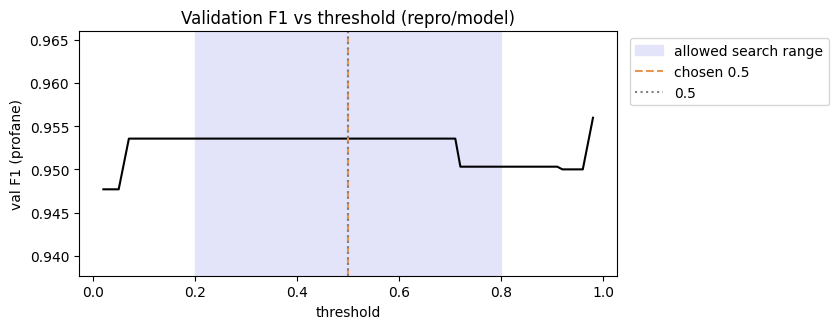

share of validation probabilities below 0.05 or above 0.95: 98%


In [12]:
from sklearn.metrics import f1_score
from src.model_utils import load_model, predict_proba

model_dir = "repro/model" if TRAINED else SUBMITTED_MODEL
tok, model, inf_cfg, device = load_model(model_dir)
val = splits["val"]
p_val = predict_proba(val.text.tolist(), tok, model, device,
                      inf_cfg["max_length"], inf_cfg["window_stride"], BASE["eval_batch_size"])
grid = np.arange(0.02, 0.99, 0.01)
f1s = [f1_score(val.label, (p_val >= t).astype(int)) for t in grid]

plt.figure(figsize=(8.5, 3.4))
plt.axvspan(0.2, 0.8, color="#E3E3FA", label="allowed search range")
plt.plot(grid, f1s, color="black")
plt.axvline(inf_cfg["threshold"], color="#E8964F", ls="--", label=f"chosen {inf_cfg['threshold']}")
plt.axvline(0.5, color="grey", ls=":", label="0.5")
plt.xlabel("threshold"); plt.ylabel("val F1 (profane)"); plt.ylim(min(f1s) - 0.01, max(f1s) + 0.01)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.title(f"Validation F1 vs threshold ({model_dir})"); plt.tight_layout(); plt.show()
print(f"share of validation probabilities below 0.05 or above 0.95: "
      f"{((p_val < 0.05) | (p_val > 0.95)).mean():.0%}")
del model; import gc; _ = gc.collect()

## 8. One evaluation on the held-out test set
The test set is used once, after the epoch, learning rate and threshold were fixed on validation.

Loading weights:   0%|                                  | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████████████████| 201/201 [00:00<00:00, 7758.87it/s]


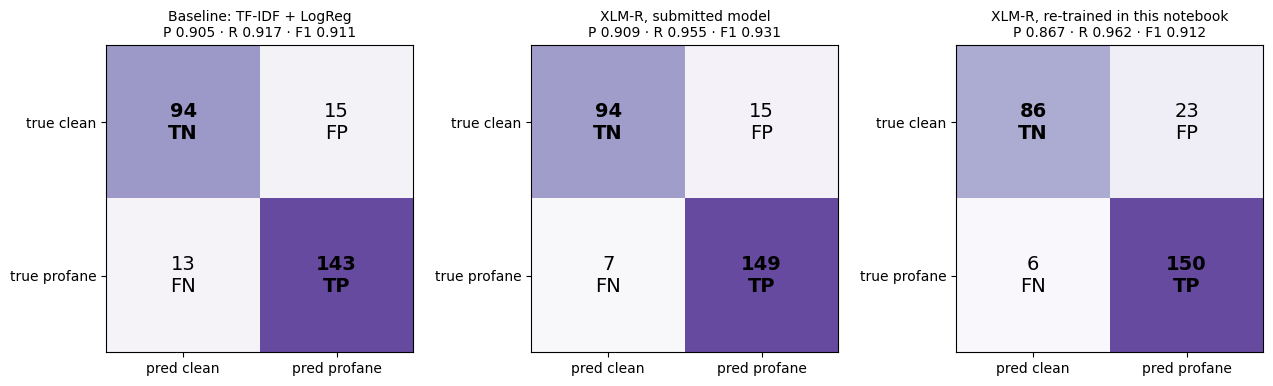

In [13]:
if TRAINED:
    !python -m src.evaluate --config $CFG > /dev/null
    retrained = json.loads(Path("repro/results/test_metrics.json").read_text())
else:
    retrained = None

def cm_array(rep):
    c = rep["confusion_matrix"]; return np.array([[c["tn"], c["fp"]], [c["fn"], c["tp"]]])

panels = [("Baseline: TF-IDF + LogReg", baseline["test"]), ("XLM-R, submitted model", rerun)]
if retrained:
    panels.append(("XLM-R, re-trained in this notebook", retrained))
fig, axes = plt.subplots(1, len(panels), figsize=(4.3 * len(panels), 3.9))
for ax, (title, rep) in zip(np.atleast_1d(axes), panels):
    m = cm_array(rep)
    ax.imshow(m, cmap="Purples", vmin=0, vmax=m.max() * 1.3)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{m[i, j]}\n{['TN', 'FP', 'FN', 'TP'][2 * i + j]}", ha="center", va="center",
                    fontsize=14, fontweight="bold" if i == j else "normal")
    ax.set_xticks([0, 1], ["pred clean", "pred profane"]); ax.set_yticks([0, 1], ["true clean", "true profane"])
    ax.set_title(f"{title}\nP {rep['precision_profane']:.3f} · R {rep['recall_profane']:.3f} · "
                 f"F1 {rep['f1_profane']:.3f}", fontsize=10)
fig.tight_layout(); plt.show()

In [14]:
# bootstrap 95% confidence interval for test F1 (1,000 resamples, seed 42)
def bootstrap_f1(pred_csv, n=1000, seed=42):
    d = pd.read_csv(pred_csv); y, p = d.label.values, d.pred.values
    rng = np.random.default_rng(seed)
    scores = [f1_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(scores, [2.5, 97.5])

lo, hi = bootstrap_f1("repro/submitted_model_results/test_predictions.csv")
print(f"submitted model: test F1 {rerun['f1_profane']:.3f}, 95% CI {lo:.3f}–{hi:.3f}")
if retrained:
    lo2, hi2 = bootstrap_f1("repro/results/test_predictions.csv")
    print(f"re-trained     : test F1 {retrained['f1_profane']:.3f}, 95% CI {lo2:.3f}–{hi2:.3f}")
print("with 156 profane test texts, one missed swear changes recall by 0.006")

submitted model: test F1 0.931, 95% CI 0.899–0.958


re-trained     : test F1 0.912, 95% CI 0.879–0.941
with 156 profane test texts, one missed swear changes recall by 0.006


## 9. Error analysis and summary

In [15]:
err_path = "repro/results/test_errors.csv" if retrained else "repro/submitted_model_results/test_errors.csv"
errors = pd.read_csv(err_path)
print(f"{len(errors)} errors in {err_path}:", errors.error.value_counts().to_dict())
errors[["error", "prob_profane", "text"]].sort_values(["error", "prob_profane"])

29 errors in repro/results/test_errors.csv: {'FP': 23, 'FN': 6}


,error,prob_profane,text
0,FN,0.0005,"Таңғажайып пернетақта. Мүмкін болса, күш қуаттарың жетсе, Қайсарларың жетсе, батыл болсаңдар, ЛАТИННИЦАНЫ ""нахуй"" ал..."
1,FN,0.0005,Ңғ табыс етті мал шаруашылығын қарқынды
2,FN,0.0007,Маған ұнамады өте нашар өтірікшілер малар
3,FN,0.0040,"Осы мечтага келип бирдеме алаиын десең сеть интернет говногой, вайфай бар и то стемиди"
4,FN,0.0109,shesheńdi mynaý ne aǵylshynsha tur sosyn stıkerdi aman bolyńdar dep jazsam am deıdi re mynaý al smaılıkter kúshti
5,FN,0.1139,Про рижим сұрай беред может бағаны билендесен про про ні котине тыгай береди
6,FP,0.5352,Esalyq жақсы жасақталған. Бырақ әмиянды баланспен толтыру қате көрсетеді. Осыны реттесеніздер. Басқалай қателік жоқ
7,FP,0.9535,"М,да тариф бағасы өсіпті. ЧЁ та басқаға ауысамын-ау. ҚЫМБАТШЫЛЫҚ жайлапты ғой. ӨЗГЕЛЕРДЕН айырмашылық қалмапты."
8,FP,0.9640,жаман емес жаксы арасында быреулер боктап сойлейтындеры болмаса болады
9,FP,0.9760,"Өте нашар, қытай сяқты жымсыма программа, саған керек есемес келмей қалды,"


In [16]:
def summary(rep):
    c = rep["confusion_matrix"]
    return {"precision": rep["precision_profane"], "recall": rep["recall_profane"], "F1": rep["f1_profane"],
            "accuracy": rep["accuracy"], "threshold": rep["threshold"], "FP": c["fp"], "FN": c["fn"]}

table = {"baseline (this notebook)": summary(baseline["test"]),
         "XLM-R submitted (README)": summary(submitted),
         "XLM-R submitted, re-run here": summary(rerun)}
if retrained:
    table["XLM-R re-trained here"] = summary(retrained)
pd.DataFrame(table).T.round(3)

,precision,recall,F1,accuracy,threshold,FP,FN
baseline (this notebook),0.905,0.917,0.911,0.894,0.41,15.0,13.0
XLM-R submitted (README),0.909,0.955,0.931,0.917,0.43,15.0,7.0
"XLM-R submitted, re-run here",0.909,0.955,0.931,0.917,0.43,15.0,7.0
XLM-R re-trained here,0.867,0.962,0.912,0.891,0.50,23.0,6.0


**Reading the summary**

* The *re-run* row must equal the *README* row exactly: it is the same model on the same data.
* The *re-trained* row differs because GPU/MPS training is not deterministic. In the committed local run the
  difference is about 0.02 F1 (0.912 vs 0.931; more false positives, slightly fewer misses). Its bootstrap CI
  overlaps the submitted one, but the run-to-run variance is as large as the gap between XLM-R and the
  baseline, so a fair comparison would average several seeds.
* The submitted XLM-R run and the baseline make the same number of false positives; XLM-R mainly reduces
  missed swears (FN).